In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [2]:
from google.colab import files

uploaded = files.upload()

In [3]:
df = pd.read_csv('Agriculture_price_dataset.csv')
df.head(10)

,STATE,District Name,Market Name,Commodity,Variety,Grade,Min_Price,Max_Price,Modal_Price,Price Date
0,Maharashtra,nashik,Lasalgaon(Niphad),Wheat,Maharashtra 2189,FAQ,2172.0,2399.0,2300.0,6/6/2023
1,Maharashtra,satara,Patan,Tomato,Other,FAQ,1000.0,1500.0,1250.0,6/6/2023
2,Uttar Pradesh,mainpuri,Bewar,Potato,Local,FAQ,800.0,820.0,810.0,6/6/2023
3,Rajasthan,chittorgarh,Nimbahera,Wheat,Other,FAQ,2040.0,2668.0,2300.0,6/6/2023
4,Rajasthan,pratapgarh,Pratapgarh,Onion,Other,FAQ,476.0,1043.0,617.0,6/6/2023
5,Rajasthan,bharatpur,Bayana,Onion,Onion,FAQ,1000.0,1000.0,1000.0,6/6/2023
6,Haryana,ambala,Naraingarh,Tomato,Tomato,FAQ,500.0,800.0,700.0,6/6/2023
7,Uttar Pradesh,pratapgarh,Pratapgarh,Onion,Other,FAQ,476.0,1043.0,617.0,6/6/2023
8,West Bengal,birbhum,Sainthia,Wheat,Other,FAQ,2150.0,2250.0,2200.0,6/6/2023
9,Himachal Pradesh,mandi,Mandi(Takoli),Tomato,Other,FAQ,1100.0,1300.0,1200.0,6/6/2023


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 737392 entries, 0 to 737391
Data columns (total 10 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   STATE          737392 non-null  object 
 1   District Name  737392 non-null  object 
 2   Market Name    737392 non-null  object 
 3   Commodity      737392 non-null  object 
 4   Variety        737392 non-null  object 
 5   Grade          737392 non-null  object 
 6   Min_Price      737392 non-null  float64
 7   Max_Price      737392 non-null  float64
 8   Modal_Price    737392 non-null  float64
 9   Price Date     737392 non-null  object 
dtypes: float64(3), object(7)
memory usage: 56.3+ MB


In [5]:
df.describe()

,Min_Price,Max_Price,Modal_Price
count,737392.000000,737392.000000,737392.000000
mean,2204.849862,2659.733824,2474.484638
std,1920.977696,2145.250773,2023.851909
min,0.000000,0.000000,0.000000
25%,1100.000000,1500.000000,1300.000000
50%,2000.000000,2300.000000,2150.000000
75%,2700.000000,3205.000000,3000.000000
max,420000.000000,480000.000000,460000.000000


In [6]:
df.isna().sum()

,0
STATE,0
District Name,0
Market Name,0
Commodity,0
Variety,0
Grade,0
Min_Price,0
Max_Price,0
Modal_Price,0
Price Date,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
cat_cols = [col for col in df.columns if df[col].dtype == 'object']
num_cols = [col for col in df.columns if df[col].dtype != 'object']
num_cols


['Min_Price', 'Max_Price', 'Modal_Price']

In [9]:
df.shape

(737392, 10)

In [10]:
df.size

7373920

In [11]:
for i in num_cols:
  print(f' {i} \n {df[i].unique()}')

 Min_Price 
 [2172. 1000.  800. ... 1947. 1306.  184.]
 Max_Price 
 [2399. 1500.  820. ...  371.  826.  643.]
 Modal_Price 
 [2300.   1250.    810.   ... 1251.31 1979.67  341.  ]


In [12]:
df.columns


Index(['STATE', 'District Name', 'Market Name', 'Commodity', 'Variety',
       'Grade', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price Date'],
      dtype='object')

In [13]:
df['STATE'].unique()

array(['Maharashtra', 'Uttar Pradesh', 'Rajasthan', 'Haryana',
       'West Bengal', 'Himachal Pradesh', 'Gujarat', 'Meghalaya',
       'Madhya Pradesh', 'Andhra Pradesh', 'Kerala', 'Nagaland', 'Orissa',
       'Karnataka', 'Assam', 'Punjab', 'Jammu & Kashmir', 'Delhi',
       'Chattisgarh', 'Bihar', ' Punjab', 'Jammu and Kashmir',
       'Chhattisgarh', 'Uttrakhand', 'Chandigarh', 'Manipur', 'Tamilnadu',
       'Tripura', 'Tamil Nadu', 'Gao'], dtype=object)

In [14]:
df['STATE'] = df['STATE'].replace(' Punjab' , 'Punjab')

In [15]:
df['STATE'].unique()

array(['Maharashtra', 'Uttar Pradesh', 'Rajasthan', 'Haryana',
       'West Bengal', 'Himachal Pradesh', 'Gujarat', 'Meghalaya',
       'Madhya Pradesh', 'Andhra Pradesh', 'Kerala', 'Nagaland', 'Orissa',
       'Karnataka', 'Assam', 'Punjab', 'Jammu & Kashmir', 'Delhi',
       'Chattisgarh', 'Bihar', 'Jammu and Kashmir', 'Chhattisgarh',
       'Uttrakhand', 'Chandigarh', 'Manipur', 'Tamilnadu', 'Tripura',
       'Tamil Nadu', 'Gao'], dtype=object)

In [16]:
df['Price Date'] = pd.to_datetime(df['Price Date'], errors='coerce')
df['Price Date'].dtype

dtype('<M8[ns]')

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 737392 entries, 0 to 737391
Data columns (total 10 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   STATE          737392 non-null  object        
 1   District Name  737392 non-null  object        
 2   Market Name    737392 non-null  object        
 3   Commodity      737392 non-null  object        
 4   Variety        737392 non-null  object        
 5   Grade          737392 non-null  object        
 6   Min_Price      737392 non-null  float64       
 7   Max_Price      737392 non-null  float64       
 8   Modal_Price    737392 non-null  float64       
 9   Price Date     737392 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(6)
memory usage: 56.3+ MB


In [18]:
price_list = zip(df['Min_Price'], df['Max_Price'])

for i, j in price_list:
    if i > j:
        print("Min Price:", i)
        print("Max Price:", j)

Min Price: 2245.0
Max Price: 0.0
Min Price: 800.0
Max Price: 0.0
Min Price: 900.0
Max Price: 0.0
Min Price: 900.0
Max Price: 0.0
Min Price: 1000.0
Max Price: 0.0
Min Price: 700.0
Max Price: 0.0
Min Price: 900.0
Max Price: 0.0
Min Price: 900.0
Max Price: 0.0
Min Price: 900.0
Max Price: 0.0
Min Price: 1000.0
Max Price: 0.0
Min Price: 1000.0
Max Price: 0.0
Min Price: 700.0
Max Price: 0.0
Min Price: 900.0
Max Price: 0.0
Min Price: 800.0
Max Price: 0.0
Min Price: 1000.0
Max Price: 0.0
Min Price: 1000.0
Max Price: 0.0
Min Price: 700.0
Max Price: 0.0
Min Price: 900.0
Max Price: 0.0
Min Price: 800.0
Max Price: 0.0
Min Price: 700.0
Max Price: 0.0
Min Price: 1000.0
Max Price: 0.0
Min Price: 2175.0
Max Price: 0.0
Min Price: 1000.0
Max Price: 0.0
Min Price: 2200.0
Max Price: 0.0
Min Price: 800.0
Max Price: 0.0
Min Price: 900.0
Max Price: 0.0
Min Price: 900.0
Max Price: 0.0
Min Price: 1000.0
Max Price: 0.0
Min Price: 700.0
Max Price: 0.0
Min Price: 1000.0
Max Price: 0.0
Min Price: 900.0
Max Price: 

In [19]:
df['Max_Price'] = df['Max_Price'].replace(0,np.nan)

In [20]:
price_list = zip(df['Min_Price'], df['Max_Price'])

for i, j in price_list:
    if i > j:
        print("Min Price:", i)
        print("Max Price:", j)

Min Price: 44.0
Max Price: 40.0
Min Price: 550.0
Max Price: 52.0


In [21]:
price_col = ['Min_Price', 'Max_Price','Modal_Price']
df[price_col].describe().round(2)


,Min_Price,Max_Price,Modal_Price
count,737392.00,736781.00,737392.00
mean,2204.85,2661.94,2474.48
std,1920.98,2144.77,2023.85
min,0.00,6.00,0.00
25%,1100.00,1500.00,1300.00
50%,2000.00,2300.00,2150.00
75%,2700.00,3210.00,3000.00
max,420000.00,480000.00,460000.00


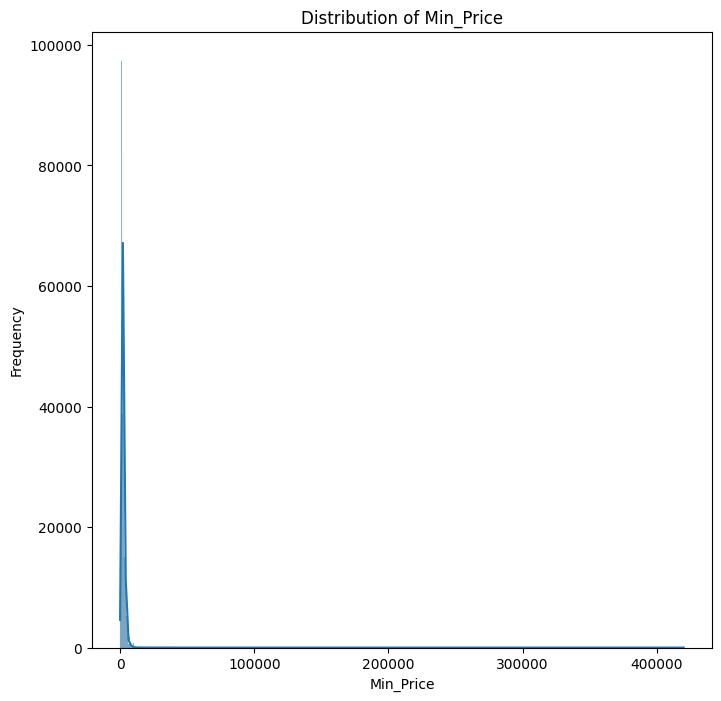

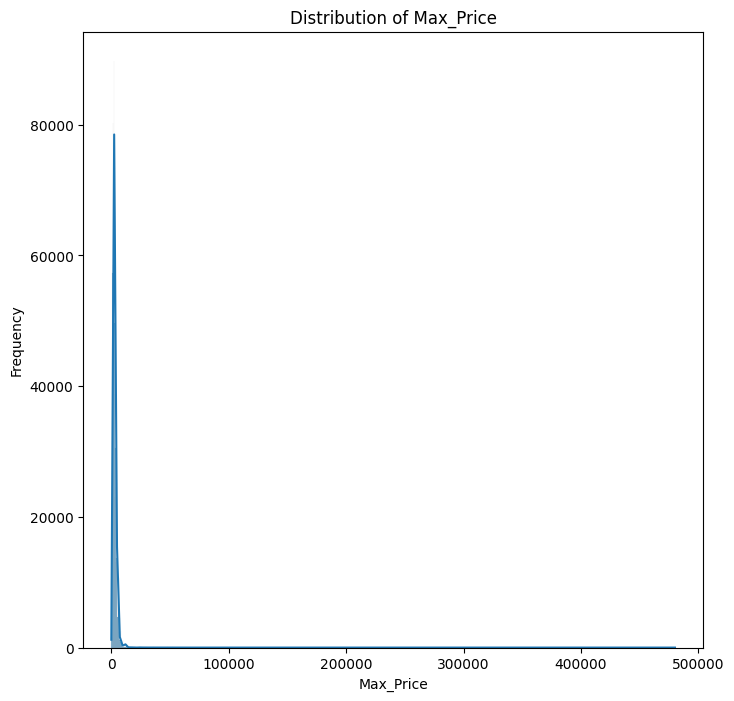

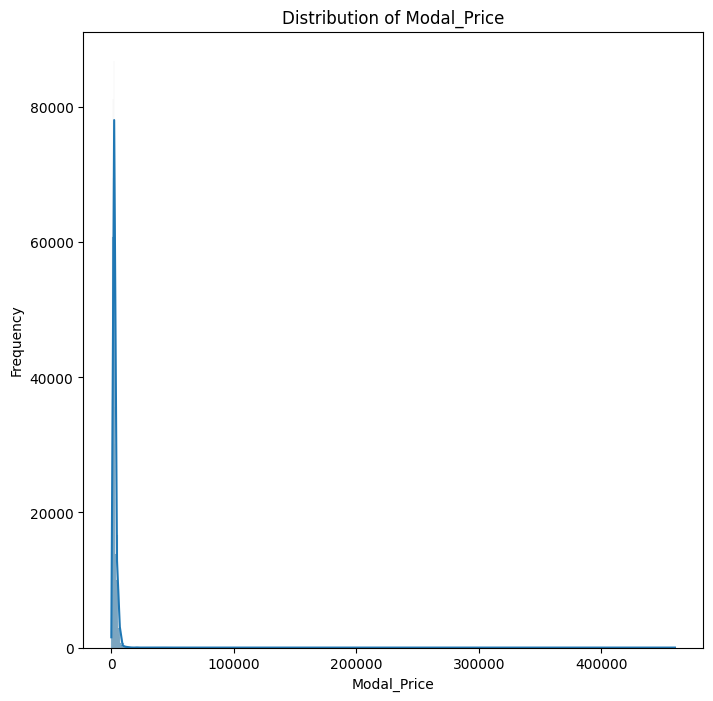

In [25]:
price_col = ['Min_Price', 'Max_Price','Modal_Price']

for i in price_col:
  plt.figure(figsize=(8, 8))
  sns.histplot(x=df[i], kde=True,data=df)
  plt.title(f'Distribution of {i}')
  plt.xlabel(i)
  plt.ylabel('Frequency')

  plt.show()


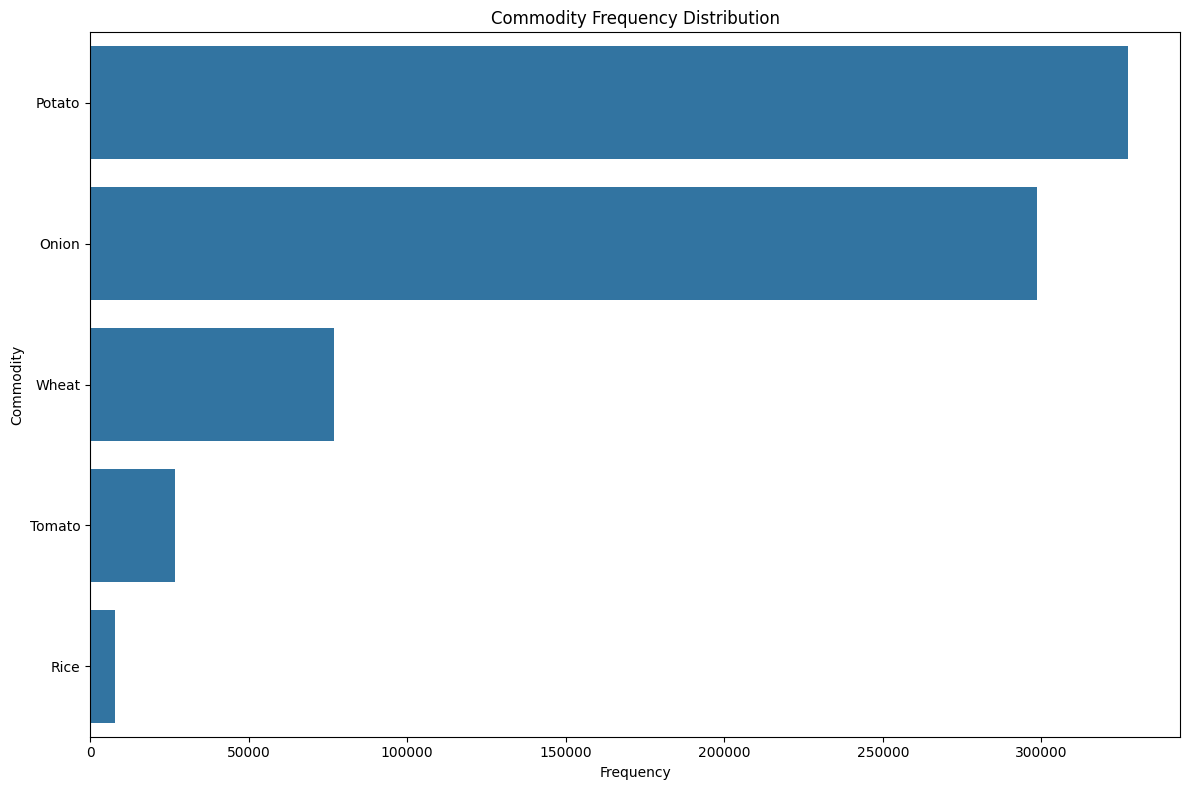

In [30]:
plt.figure(figsize=(12, 8))

sns.countplot(data=df,y='Commodity',order=df['Commodity'].value_counts().index)

plt.title('Commodity Frequency Distribution')
plt.xlabel('Frequency')
plt.ylabel('Commodity')

plt.tight_layout()
plt.show()

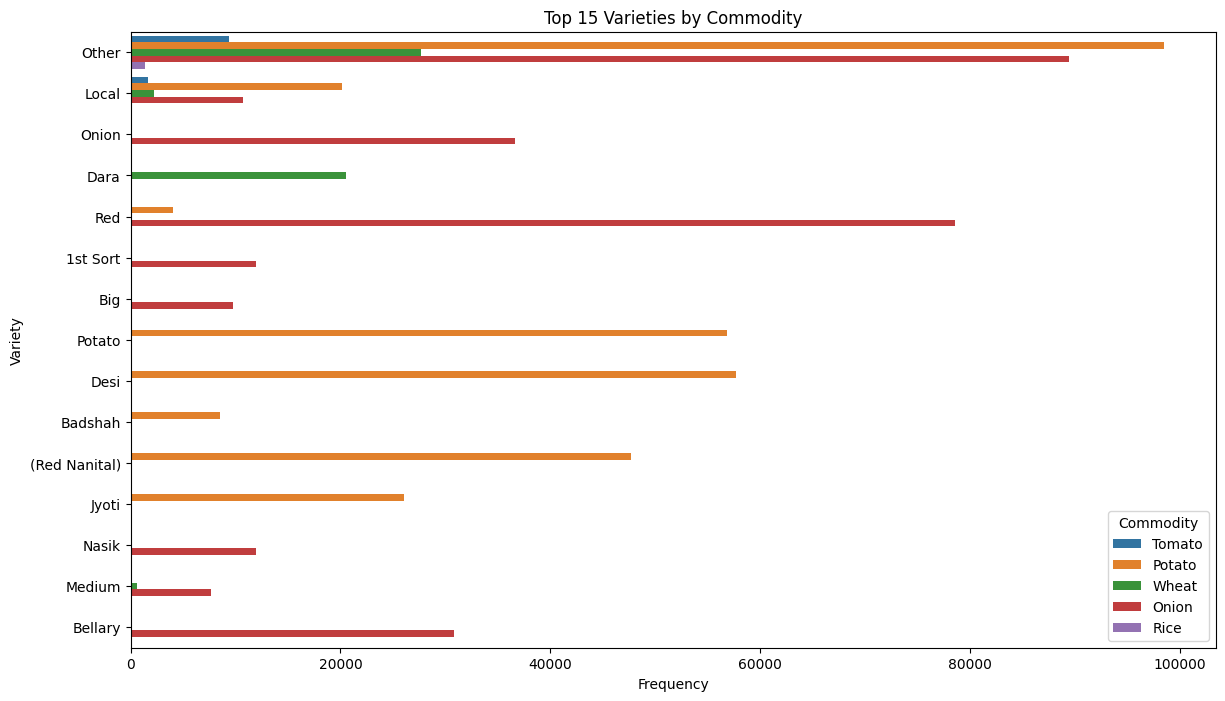

In [32]:
plt.figure(figsize=(14, 8))

top_varieties = df['Variety'].value_counts().head(15).index

sns.countplot(
    data=df[df['Variety'].isin(top_varieties)],
    y='Variety',
    hue='Commodity'
)

plt.title('Top 15 Varieties by Commodity')
plt.xlabel('Frequency')
plt.ylabel('Variety')

plt.show()

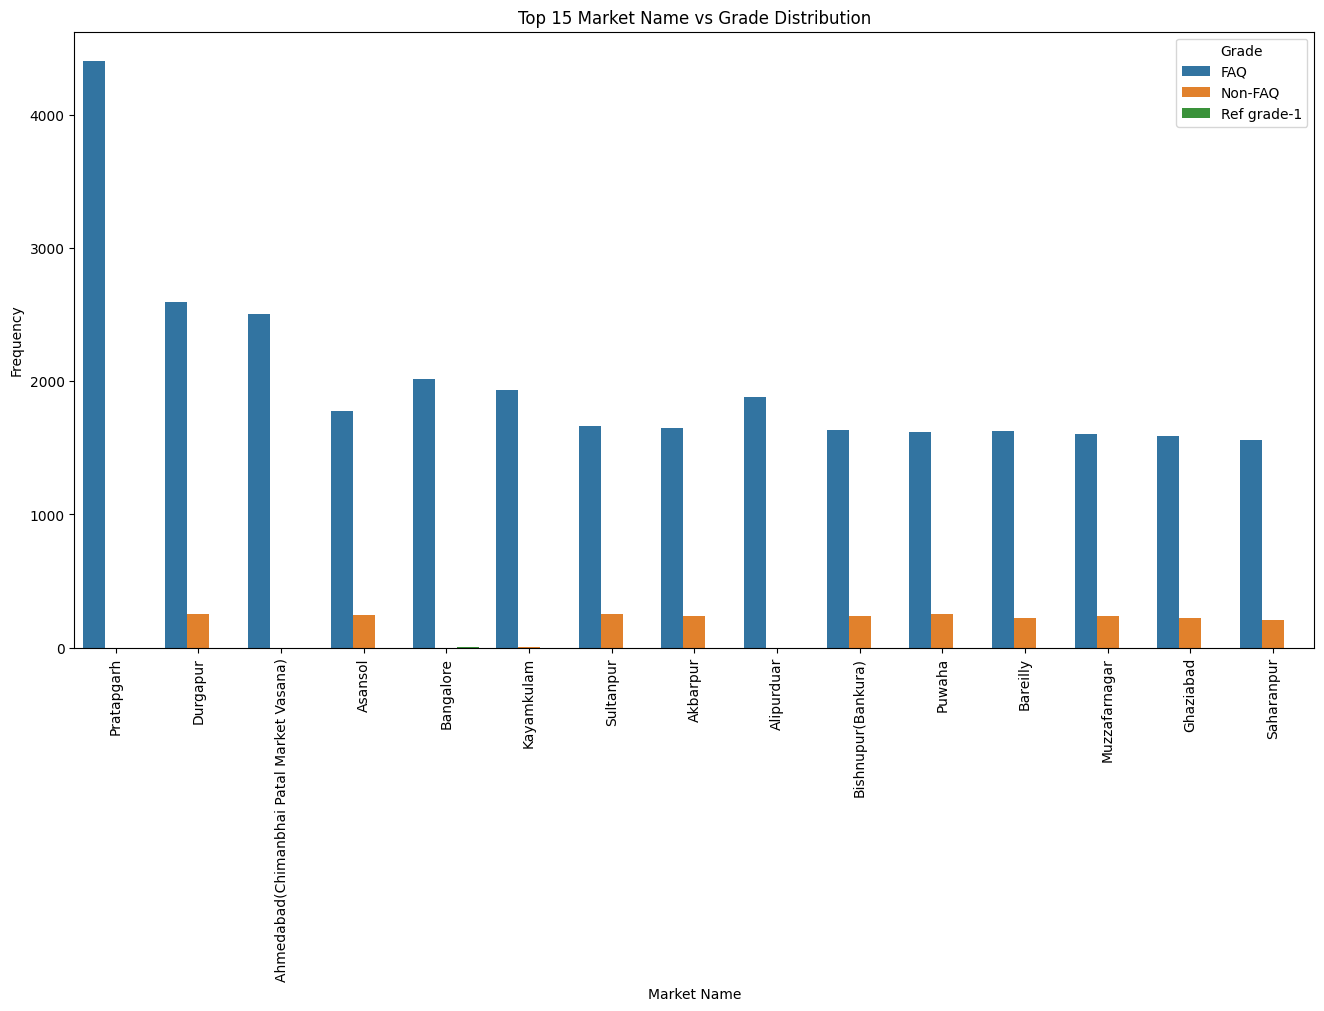

In [38]:

top_15_markets = df['Market Name'].value_counts().head(15).index

df_top15 = df[df['Market Name'].isin(top_15_markets)]

plt.figure(figsize=(16, 8))

sns.countplot(data=df_top15,x='Market Name',hue='Grade',order=top_15_markets)

plt.title('Top 15 Market Name vs Grade Distribution')
plt.xlabel('Market Name')
plt.ylabel('Frequency')

plt.xticks(rotation=90)
plt.legend(title='Grade')

plt.show()

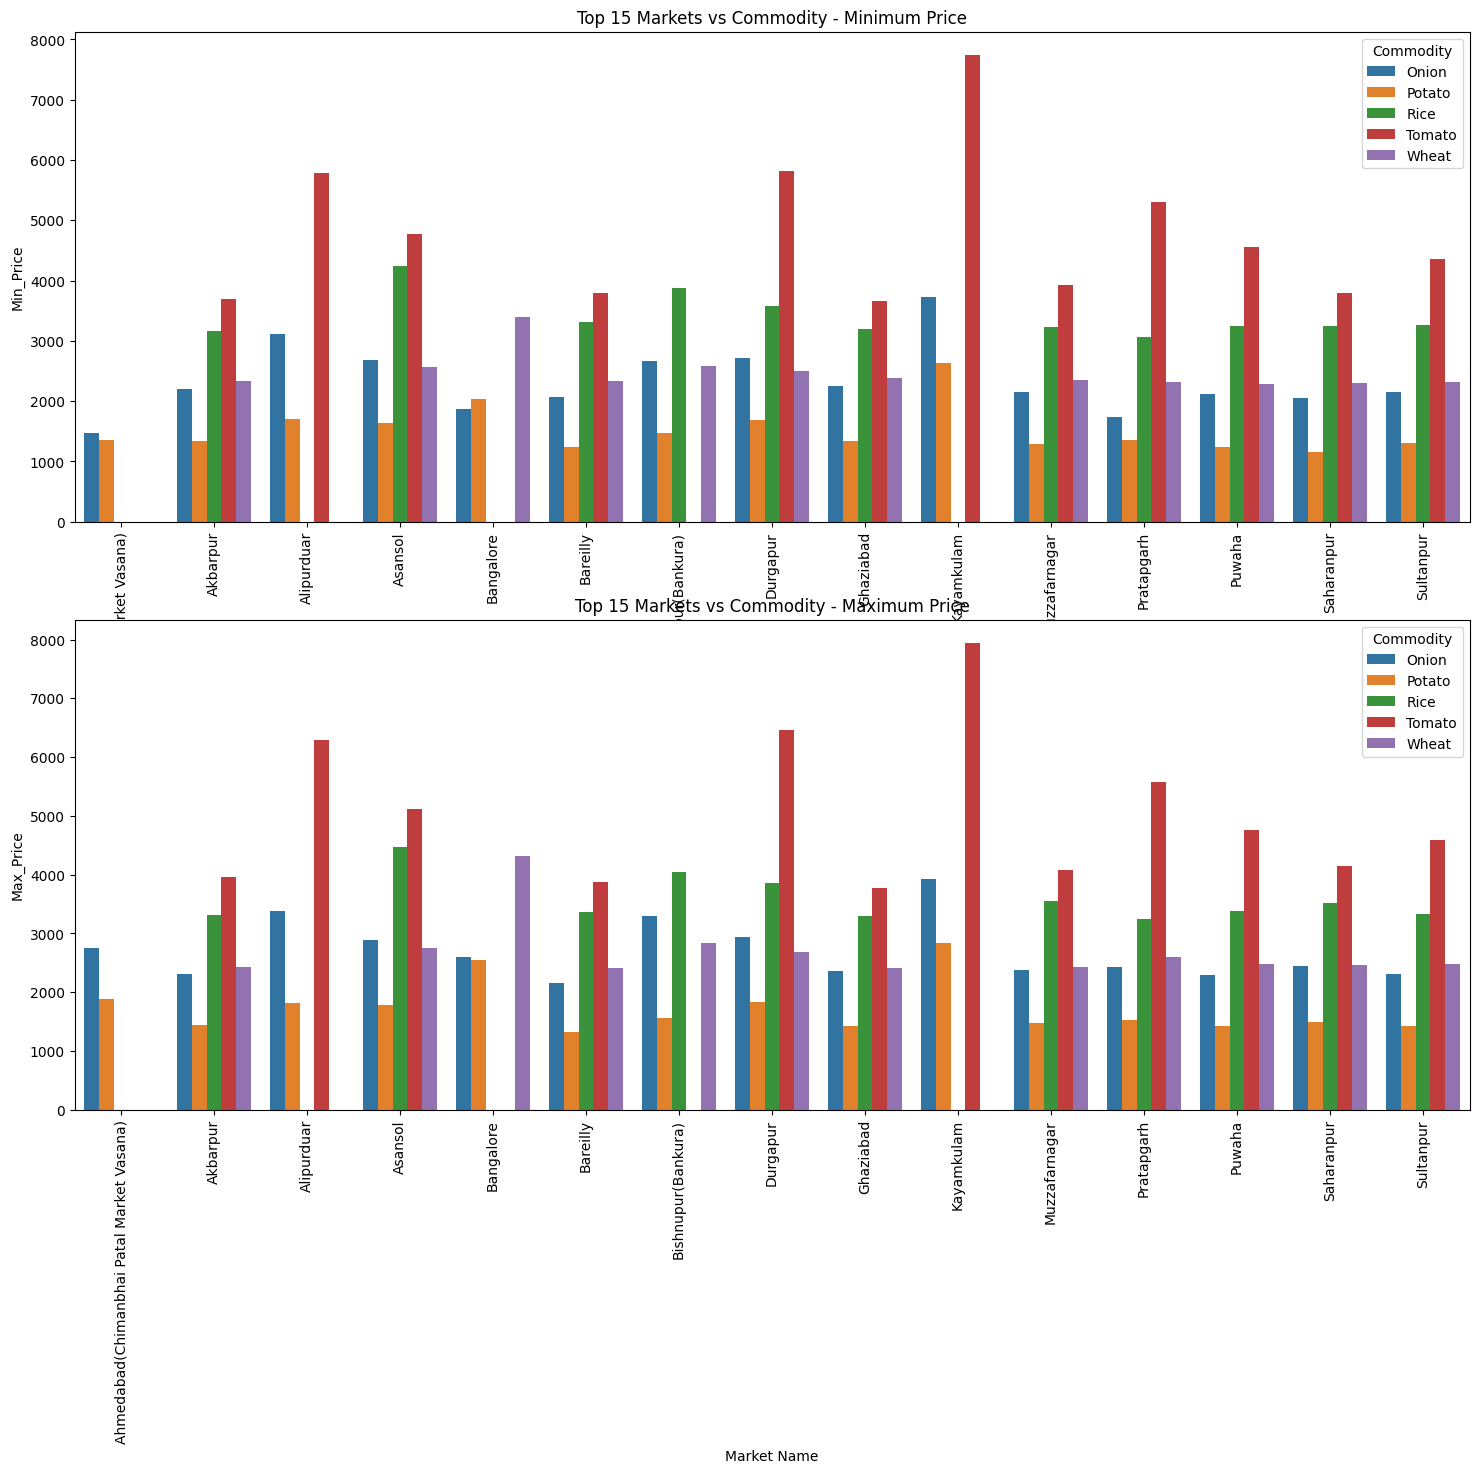

In [44]:

top_15_markets = df['Market Name'].value_counts().head(15).index


df_top15 = df[df['Market Name'].isin(top_15_markets)]


price_data = df_top15.groupby(
    ['Market Name', 'Commodity']
)[['Min_Price', 'Max_Price']].mean().reset_index()


fig, axes = plt.subplots(2, 1, figsize=(18, 14))

sns.barplot(
    data=price_data,
    x='Market Name',
    y='Min_Price',
    hue='Commodity',
    ax=axes[0]
)

axes[0].set_title('Top 15 Markets vs Commodity - Minimum Price')
axes[0].tick_params(axis='x', rotation=90)

sns.barplot(
    data=price_data,
    x='Market Name',
    y='Max_Price',
    hue='Commodity',
    ax=axes[1]
)

axes[1].set_title('Top 15 Markets vs Commodity - Maximum Price')
axes[1].tick_params(axis='x', rotation=90)


plt.show()

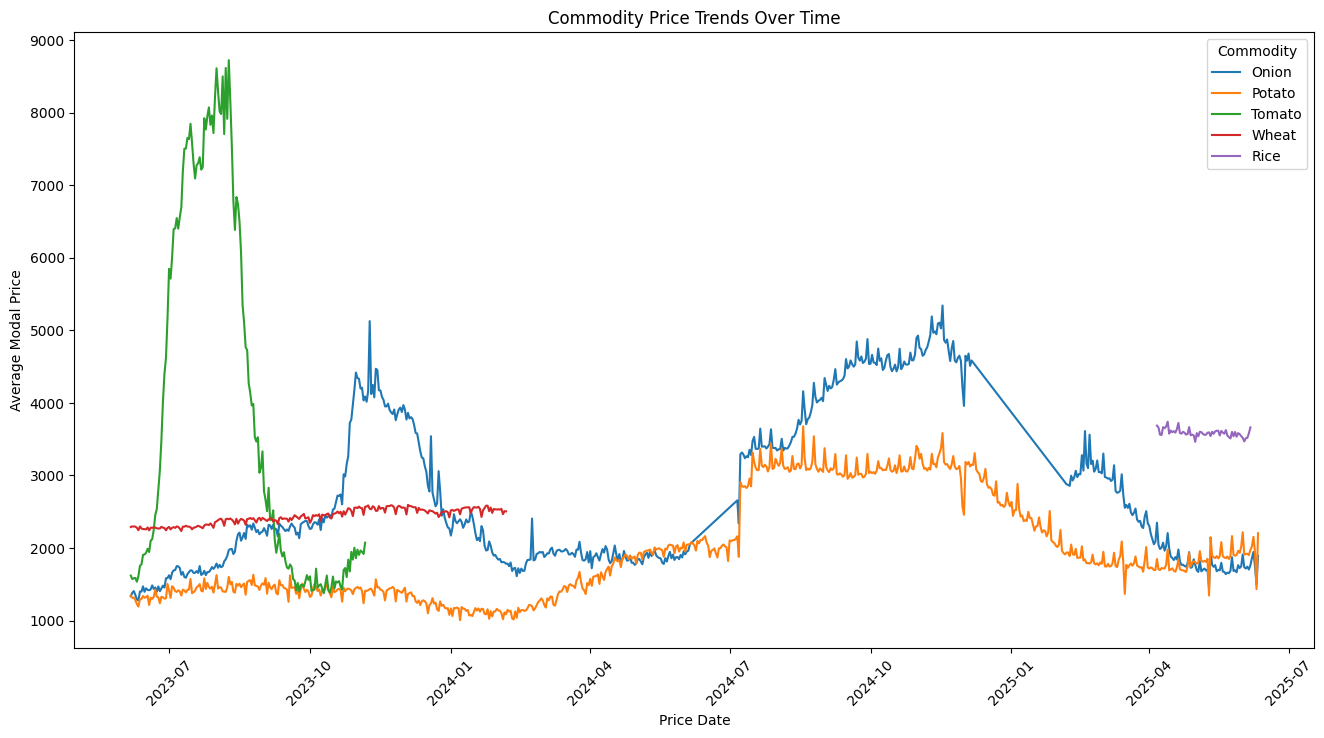

In [45]:

df['Price Date'] = pd.to_datetime(df['Price Date'])


top_commodities = df['Commodity'].value_counts().head(5).index

df_trend = df[df['Commodity'].isin(top_commodities)]

trend_data = df_trend.groupby(['Price Date', 'Commodity'])['Modal_Price'].mean().reset_index()

plt.figure(figsize=(16, 8))

sns.lineplot(data=trend_data,x='Price Date',y='Modal_Price',hue='Commodity')

plt.title('Commodity Price Trends Over Time')
plt.xlabel('Price Date')
plt.ylabel('Average Modal Price')
plt.xticks(rotation=45)
plt.show()

In [47]:

df.to_csv('Mandi_Cleaned_Data.csv',index=False)

In [48]:
from google.colab import files

files.download('Mandi_Cleaned_Data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>